In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score

In [7]:
df=pd.read_csv("Data/car_fused_filled.csv").drop(columns=["Unnamed: 0","Modele"])
#df.loc[:,"Chevaux"]=df.loc[:,"Chevaux"].fillna(df.loc[:,"Chevaux"].mean())
df=df.loc[df.Prix<50000]

In [11]:
df.columns

Index(['Marque', 'Prix', 'Energie', 'Kilometre', 'Annee', 'Boites de vitesse',
       'Chevaux', 'type', 'PrixNeuf', 'bluetooth', 'cam_recul', 'clim_auto',
       'feux_led', 'gps', 'inte_cuir', 'isofix', 'jantes_alliage',
       'radar_recul', 'regulateur_vitesse', 'tete_haute', 'toit_ouvrant',
       'toit_panoramique', 'trois_siege_indiv'],
      dtype='object')

In [13]:
df.Marque.unique()

array(['RENAULT', 'JEEP', 'TOYOTA', 'FORD', 'FIAT', 'NISSAN',
       'LAND-ROVER', 'BMW', 'PEUGEOT', 'CITROEN', 'DACIA', 'DS', 'OPEL',
       'VOLKSWAGEN', 'SEAT', 'MINI', 'MITSUBISHI', 'SUZUKI', 'CUPRA',
       'KIA', 'ALFA ROMEO', 'HYUNDAI', 'AUDI', 'MERCEDES', 'VOLVO',
       'MAZDA', 'SKODA', 'LEXUS', 'JAGUAR', 'HONDA', 'SMART', 'ABARTH',
       'MG', 'INFINITI', 'MASERATI', 'ASTON MARTIN', 'LYNK & CO', 'TESLA',
       'SUBARU', 'IVECO', 'FUSO'], dtype=object)

In [15]:
df.Energie.unique()

array(['Diesel', 'Essence M', 'Essence', 'Hybride R', 'Essence B',
       'Electrique', 'Hybride', 'Gpl', 'Diesel M', 'Gnv'], dtype=object)

In [17]:
df['Boites de vitesse'].unique()

array(['Manuelle', 'Automatique'], dtype=object)

In [19]:
df.isna().sum()

Marque                0
Prix                  0
Energie               0
Kilometre             0
Annee                 0
Boites de vitesse     0
Chevaux               0
type                  0
PrixNeuf              0
bluetooth             0
cam_recul             0
clim_auto             0
feux_led              0
gps                   0
inte_cuir             0
isofix                0
jantes_alliage        0
radar_recul           0
regulateur_vitesse    0
tete_haute            0
toit_ouvrant          0
toit_panoramique      0
trois_siege_indiv     0
dtype: int64

In [21]:
df.dtypes

Marque                 object
Prix                    int64
Energie                object
Kilometre               int64
Annee                   int64
Boites de vitesse      object
Chevaux               float64
type                   object
PrixNeuf              float64
bluetooth                bool
cam_recul                bool
clim_auto                bool
feux_led                 bool
gps                      bool
inte_cuir                bool
isofix                   bool
jantes_alliage           bool
radar_recul              bool
regulateur_vitesse       bool
tete_haute               bool
toit_ouvrant             bool
toit_panoramique         bool
trois_siege_indiv        bool
dtype: object

In [23]:
cat_data=df.dtypes.loc[df.dtypes=="object"].index
num_data=df.dtypes.loc[df.dtypes!="object"].index[1:]

In [25]:
num_data,cat_data

(Index(['Kilometre', 'Annee', 'Chevaux', 'PrixNeuf', 'bluetooth', 'cam_recul',
        'clim_auto', 'feux_led', 'gps', 'inte_cuir', 'isofix', 'jantes_alliage',
        'radar_recul', 'regulateur_vitesse', 'tete_haute', 'toit_ouvrant',
        'toit_panoramique', 'trois_siege_indiv'],
       dtype='object'),
 Index(['Marque', 'Energie', 'Boites de vitesse', 'type'], dtype='object'))

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import FunctionTransformer
import xgboost as xgb

from sklearn.linear_model import LinearRegression, LogisticRegressionCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor,RandomTreesEmbedding
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor
import pickle
from lightgbm import LGBMRegressor

In [28]:
#Preprocessing
C1=ColumnTransformer([("prix",'passthrough',["Prix"]),
                      ("ohe", OneHotEncoder(handle_unknown="ignore",sparse_output=False), cat_data),
                      ("num",StandardScaler(),num_data)])


P=Pipeline([("Transform", C1)])#,("P",C2)])

In [29]:
train,test=train_test_split(df,train_size=0.8,random_state=42)
test=test.loc[test.Kilometre!=0]

In [30]:
T=C1.fit_transform(train)#test preprocessing

In [35]:
P.fit(train)
with open('Models/Preprocessor.pkl', 'wb') as f:
              pickle.dump(P,f)

In [37]:
df_train=P.transform(train)
df_test=P.transform(test)

In [39]:
df_train.shape

(11821, 81)

In [41]:
X_train=df_train[:,1:]
X_test=df_test[:,1:]
Y_train=df_train[:,0].ravel()
Y_test=df_test[:,0].ravel()

In [43]:
np.save("Data/X_test.npy",X_test)
np.save("Data/Y_test.npy",Y_test)
np.save("Data/features.npy",np.array(list(cat_data)+list(num_data)))

In [45]:
X_train.shape,Y_train.shape,X_test.shape,Y_test.shape

((11821, 80), (11821,), (2956, 80), (2956,))

# Fitting du modèle

In [49]:

#R=DecisionTreeRegressor()
"""
R=RandomForestRegressor(**{'max_depth': 10,
  'min_samples_leaf': 1,
  'min_samples_split': 3,
  'warm_start': True})
"""
#R=Ridge()
#R=KNeighborsRegressor()
#R=SVR(C=0.01)
#R=LinearRegression()
#R=LogisticRegressionCV(cv=2)
#R=GradientBoostingRegressor()
#R=HistGradientBoostingRegressor(l2_regularization=10)
param={'gamma': 5,
  'learning_rate': 0.01,
  'max_depth': 5,
  'n_estimators': 10000,
  'reg_alpha': 10,
  'reg_lambda': 1}


R=XGBRegressor(**param)

In [51]:
R.fit(X_train,Y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=5, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.01, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=5, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=10000, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [53]:
R.save_model('Models/model_prediction_car_price.json')

In [54]:
y_pred_train=R.predict(X_train)
y_pred_test=R.predict(X_test)

In [57]:
from sklearn.metrics import root_mean_squared_error as RMSE
from sklearn.metrics import mean_absolute_error as MAE
from sklearn.metrics import mean_absolute_percentage_error as MAPE
from sklearn.metrics import r2_score

In [59]:
dic={"RMSE":[RMSE(Y_train,y_pred_train),RMSE(Y_test,y_pred_test)],"MAE":[MAE(Y_train,y_pred_train),MAE(Y_test,y_pred_test)],
 "MAPE":[MAPE(Y_train,y_pred_train),MAPE(Y_test,y_pred_test)],"r2":[r2_score(Y_train,y_pred_train),r2_score(Y_test,y_pred_test)]}
df_score=pd.DataFrame(dic)
df_score.index=["train","test"]
df_score.to_csv("Data/score_model.csv")
df_score

,RMSE,MAE,MAPE,r2
train,1550.931336,1088.753936,0.051488,0.971487
test,2375.697209,1567.465483,0.069353,0.934778


In [61]:
#variance prix, moyenne prix
Y_train.std(),Y_train.mean()

(9184.77235735354, 22145.369511885627)

# Learning Curve

Text(0.5, 1.0, 'Learning Curve for XGBRegressor')

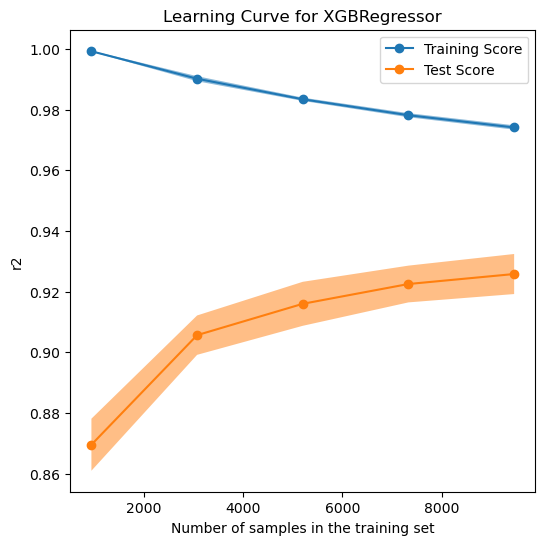

In [87]:
from sklearn.model_selection import LearningCurveDisplay, ShuffleSplit
import matplotlib.pyplot as plt
fig,ax= plt.subplots(1,1,figsize=(6, 6))

common_params = {
    "X": X_train,
    "y": Y_train,
    "train_sizes": np.linspace(0.1, 1.0, 5),
    "cv": ShuffleSplit(n_splits=10, test_size=0.2, random_state=0),
    "score_type": "both",
    "n_jobs": 4,
    "line_kw": {"marker": "o"},
    "std_display_style": "fill_between",
    "score_name": "r2",
    "scoring":"r2"
}
LearningCurveDisplay.from_estimator(R, **common_params,ax=ax)
handles, label = ax.get_legend_handles_labels()
ax.legend(handles[:2], ["Training Score", "Test Score"])
ax.set_title(f"Learning Curve for {R.__class__.__name__}")

In [95]:
fig.savefig("Data/learning_curve.png")

# Dummy model

In [37]:
#dummy modèle, on prédit uniquement par la moyenne des prix
RMSE(Y_train,Y_train*0+Y_train.mean())

9184.77235735354

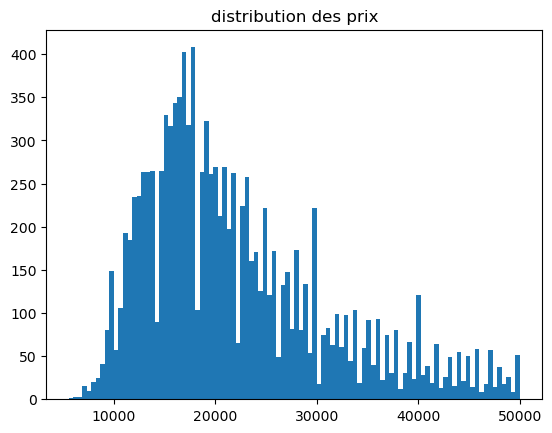

In [39]:
plt.hist(Y_train,bins=100)
plt.title("distribution des prix")
plt.show()

Test véhicule custom

In [42]:
voiture={"Kilometre":140000,"Annee":2014,"Marque":'HYUNDAI',"Energie":"Diesel","PrixNeuf":22000,"Boites de vitesse":"Manuelle",
        "Chevaux":75,"bluetooth":True,"cam_recul":False,"clim_auto":True,"feux_led":True,"gps":False,
        "inte_cuir":False,"isofix":True,"jantes_alliage":True,"regulateur_vitesse":True,"tete_haute":False,
        "toit_ouvrant":True,"toit_panoramique":True,"trois_siege_indiv":False,"radar_recul":True,"type":"berline","Modele":"","Prix":10000}
voiture={k:[voiture[k]] for k in voiture}
df_voiture=pd.DataFrame(voiture)[train.columns]
V=P.transform(df_voiture)[:,1:]
V.shape
R.predict(V)

array([9107.37], dtype=float32)

# Affichage des performances du modèle selon la marque

In [44]:
df.Marque.unique()

array(['RENAULT', 'JEEP', 'TOYOTA', 'FORD', 'FIAT', 'NISSAN',
       'LAND-ROVER', 'BMW', 'PEUGEOT', 'CITROEN', 'DACIA', 'DS', 'OPEL',
       'VOLKSWAGEN', 'SEAT', 'MINI', 'MITSUBISHI', 'SUZUKI', 'CUPRA',
       'KIA', 'ALFA ROMEO', 'HYUNDAI', 'AUDI', 'MERCEDES', 'VOLVO',
       'MAZDA', 'SKODA', 'LEXUS', 'JAGUAR', 'HONDA', 'SMART', 'ABARTH',
       'MG', 'INFINITI', 'MASERATI', 'ASTON MARTIN', 'LYNK & CO', 'TESLA',
       'SUBARU', 'IVECO', 'FUSO'], dtype=object)

In [46]:
M="BMW"

In [48]:
train=train[['Prix', 'Marque',  'Energie', 'Kilometre', 'Annee',
       'Boites de vitesse', 'Chevaux', 'type', 'PrixNeuf', 'bluetooth',
       'cam_recul', 'clim_auto', 'feux_led', 'gps', 'inte_cuir', 'isofix',
       'jantes_alliage', 'radar_recul', 'regulateur_vitesse', 'tete_haute',
       'toit_ouvrant', 'toit_panoramique', 'trois_siege_indiv']]
test=test[['Prix','Marque',  'Energie', 'Kilometre', 'Annee',
       'Boites de vitesse', 'Chevaux', 'type', 'PrixNeuf', 'bluetooth',
       'cam_recul', 'clim_auto', 'feux_led', 'gps', 'inte_cuir', 'isofix',
       'jantes_alliage', 'radar_recul', 'regulateur_vitesse', 'tete_haute',
       'toit_ouvrant', 'toit_panoramique', 'trois_siege_indiv']]
df_bis=P.transform(train.loc[train.Marque==M])
df_bis_test=P.transform(test.loc[test.Marque==M])

Y_bis=df_bis[:,0]
X_bis=df_bis[:,1:]

Y_bis_test=df_bis_test[:,0]
X_bis_test=df_bis_test[:,1:]

In [50]:
y_pred_bis=R.predict(X_bis)
y_pred_bis_test=R.predict(X_bis_test)

In [52]:
dic={"RMSE":[RMSE(Y_bis,y_pred_bis),RMSE(Y_bis_test,y_pred_bis_test)],"MAE":[MAE(Y_bis,y_pred_bis),MAE(Y_bis_test,y_pred_bis_test)],
 "MAPE":[MAPE(Y_bis,y_pred_bis),MAPE(Y_bis_test,y_pred_bis_test)]}
df_score=pd.DataFrame(dic)
df_score.index=["train","test"]
print("\t\t",M)
df_score

		 BMW


,RMSE,MAE,MAPE
train,1275.766371,983.010965,0.032954
test,3698.914208,2715.812975,0.082198


In [54]:
S=df.Prix.loc[df.Marque==M]

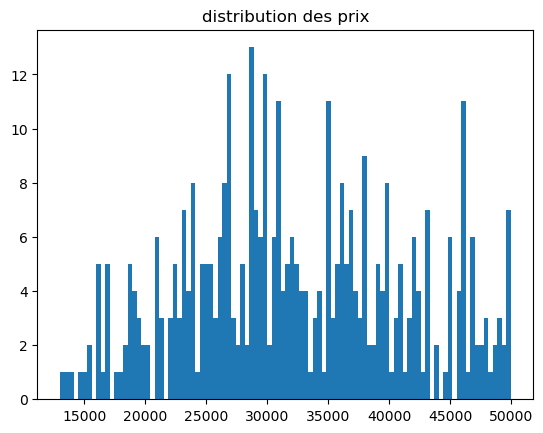

In [56]:
plt.hist(S,bins=100)
plt.title("distribution des prix")
plt.show()

# Affichage des performances du modèle selon le type de véhicule


In [59]:
df.type.unique()

array(['4x4', 'berline', 'break', 'cabriolet', 'coupe', 'coupecabriolet',
       'monospace', 'suv', 'utilitaire'], dtype=object)

In [61]:
M="berline"

In [63]:
train=train[['Prix', 'Marque',  'Energie', 'Kilometre', 'Annee',
       'Boites de vitesse', 'Chevaux', 'type', 'PrixNeuf', 'bluetooth',
       'cam_recul', 'clim_auto', 'feux_led', 'gps', 'inte_cuir', 'isofix',
       'jantes_alliage', 'radar_recul', 'regulateur_vitesse', 'tete_haute',
       'toit_ouvrant', 'toit_panoramique', 'trois_siege_indiv']]
test=test[['Prix', 'Marque',  'Energie', 'Kilometre', 'Annee',
       'Boites de vitesse', 'Chevaux', 'type', 'PrixNeuf', 'bluetooth',
       'cam_recul', 'clim_auto', 'feux_led', 'gps', 'inte_cuir', 'isofix',
       'jantes_alliage', 'radar_recul', 'regulateur_vitesse', 'tete_haute',
       'toit_ouvrant', 'toit_panoramique', 'trois_siege_indiv']]
df_bis=P.transform(train.loc[train.type==M])
df_bis_test=P.transform(test.loc[test.type==M])

Y_bis=df_bis[:,0]
X_bis=df_bis[:,1:]

Y_bis_test=df_bis_test[:,0]
X_bis_test=df_bis_test[:,1:]

In [65]:
y_pred_bis=R.predict(X_bis)
y_pred_bis_test=R.predict(X_bis_test)

In [66]:
dic={"RMSE":[RMSE(Y_bis,y_pred_bis),RMSE(Y_bis_test,y_pred_bis_test)],"MAE":[MAE(Y_bis,y_pred_bis),MAE(Y_bis_test,y_pred_bis_test)],
 "MAPE":[MAPE(Y_bis,y_pred_bis),MAPE(Y_bis_test,y_pred_bis_test)]}
df_score=pd.DataFrame(dic)
df_score.index=["train","test"]
print("\t\t",M)
df_score

		 berline


,RMSE,MAE,MAPE
train,1295.268052,901.344393,0.050928
test,1976.803412,1240.183971,0.063033


In [69]:
S=df.Prix.loc[df.type==M]

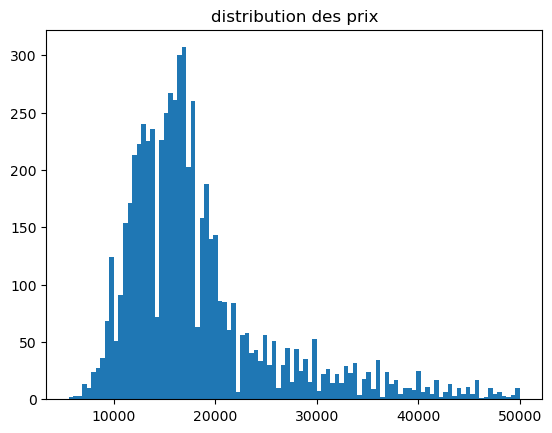

In [71]:
plt.hist(S,bins=100)
plt.title("distribution des prix")
plt.show()